<a href="https://colab.research.google.com/github/Andru-1987/data_science_ii_96085/blob/main/14_semana/clase_teorica/ML_Semana_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 # Validación y Problemas en Machine Learning


El objetivo central de la evaluación de modelos no es maximizar el desempeño sobre datos conocidos, sino estimar y mejorar la **capacidad de generalización** sobre datos no vistos. El equilibrio entre sesgo y varianza, junto con un esquema de validación adecuado, determina si un modelo está subajustado, sobreajustado o correctamente calibrado. [statisticallearning](https://statisticallearning.org/bias-variance-tradeoff.html)



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge

from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


## Columnas de nuestro dataset de buenos aires.

| Columna | Qué es | Notas y uso en el análisis |
|---|---|---|
| `id` | Identificador único del aviso | Solo identificador, no se usa como variable |
| `name` | Título del aviso | Texto libre, no se usó |
| `host_id` | Identificador del anfitrión | Sirve para agrupar avisos por host (por ejemplo, auditar a los profesionales) |
| `host_profile_id` | Identificador del perfil del anfitrión | Identificador, no se usó |
| `host_name` | Nombre del anfitrión | No se usó |
| `neighbourhood_group` | Agrupación de barrios | 100% nulo, se descartó |
| `neighbourhood` | Barrio del aviso | Se usó para KPIs y para calcular `precio_rel` (precio contra pares del mismo barrio) |
| `latitude`, `longitude` | Coordenadas del aviso | Se usaron para calcular `dist_centro_km`, la distancia al Obelisco |
| `room_type` | Tipo de alojamiento: departamento entero, habitación privada, compartida o de hotel | 90% son departamentos enteros. Se usó en el perfilado y en `precio_rel` |
| `price` | Precio por noche en ARS | 7% nulo (esas filas se eliminaron). Tiene outliers extremos, hasta ARS 160M, por eso se winsorizó entre p1 y p99 |
| `minimum_nights` | Mínimo de noches por reserva | Base de la regla de estadía larga (30 noches o más) |
| `number_of_reviews` | Cantidad total de reviews históricas | Proxy de antigüedad y demanda acumulada |
| `last_review` | Fecha de la última review | 12% nulo, que significa "nunca tuvo reviews". Se convirtió en días desde la última review |
| `reviews_per_month` | Promedio de reviews por mes | Nulo cuando no hay reviews, se imputó con 0 |
| `calculated_host_listings_count` | Cantidad de avisos que tiene el mismo host | Define "host profesional" (5 o más avisos) |
| `availability_365` | Días disponibles en los próximos 365 | Más bajo suele implicar más ocupación, pero es solo un proxy |
| `number_of_reviews_ltm` | Reviews de los últimos 12 meses (LTM = last twelve months) | Es la mejor señal de demanda reciente. Base de la regla de inactivo (0 reviews LTM) |
| `license` | Licencia o registro de alojamiento | 98% nulo, se descartó |



In [ ]:
url:str = "https://raw.githubusercontent.com/Andru-1987/csv_files_ds/refs/heads/main/buenos_aires.csv"
target:str = 'price'
RANDOM_STATE=42

# Carga y limpieza básica inicial (drop target NaN)
df = pd.read_csv(url)
df = df.drop(columns=['id', 'name', 'host_id', 'host_profile_id', 'host_name', 'neighbourhood_group', 'license'])
df = df.drop_duplicates()
df = df.dropna(subset=[target]) # El target debe estar disponible
pd.set_option('display.float_format', '{:.2f}'.format)

In [ ]:
df.sample(10)

,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
26799,Palermo,-34.577460,-58.410520,Private room,59624.0,1.0,6,2026-09-17,1.53,1,221,6
3294,Palermo,-34.581320,-58.427890,Entire home/apt,124269.0,2.0,4,2026-01-31,0.04,3,13,2
6485,Belgrano,-34.560340,-58.460700,Private room,40841.0,7.0,32,2026-03-21,0.56,9,326,3
28411,Palermo,-34.576583,-58.424189,Entire home/apt,81537.0,3.0,0,NaN,NaN,26,331,0
29243,Almagro,-34.598500,-58.427700,Entire home/apt,120054.0,2.0,0,NaN,NaN,16,362,0
12229,Agronomia,-34.596285,-58.498081,Entire home/apt,119248.0,1.0,15,2025-12-10,0.40,57,341,2
14724,Villa Devoto,-34.597751,-58.512566,Entire home/apt,136065.0,1.0,44,2026-09-09,1.50,1,31,19
16295,Palermo,-34.576105,-58.420001,Entire home/apt,84085.0,2.0,241,2026-09-16,8.33,3,98,102
15701,Retiro,-34.594960,-58.386140,Entire home/apt,85683.0,2.0,70,2026-09-17,2.31,1,332,36
3256,Palermo,-34.597234,-58.420340,Entire home/apt,99373.0,1.0,173,2026-09-12,1.82,1,217,31


In [ ]:
df.price.describe().round(2)

,price
count,2.758900e+04
mean,2.778610e+05
std,3.548062e+06
min,2.470000e+02
25%,7.949900e+04
50%,1.062530e+05
75%,1.484480e+05
max,1.605638e+08


### Analisis de outliers

In [ ]:
# --- 1. Método IQR sobre Log1p ---
log_prices = np.log1p(df[target])
q1_log, q3_log = log_prices.quantile(0.25), log_prices.quantile(0.75)
iqr_log = q3_log - q1_log
lower_log, upper_log = np.expm1(q1_log - 1.5 * iqr_log), np.expm1(q3_log + 1.5 * iqr_log)
mask_iqr = (df[target] >= lower_log) & (df[target] <= upper_log)

# --- 2. Método Percentiles (1% - 99%) ---
p_low, p_high = df[target].quantile(0.01), df[target].quantile(0.99)
mask_perc = (df[target] >= p_low) & (df[target] <= p_high)

# --- 3. Método Isolation Forest (3% contaminación) ---
iso = IsolationForest(contamination=0.03, random_state=RANDOM_STATE)
mask_iso = iso.fit_predict(df[[target]]) == 1

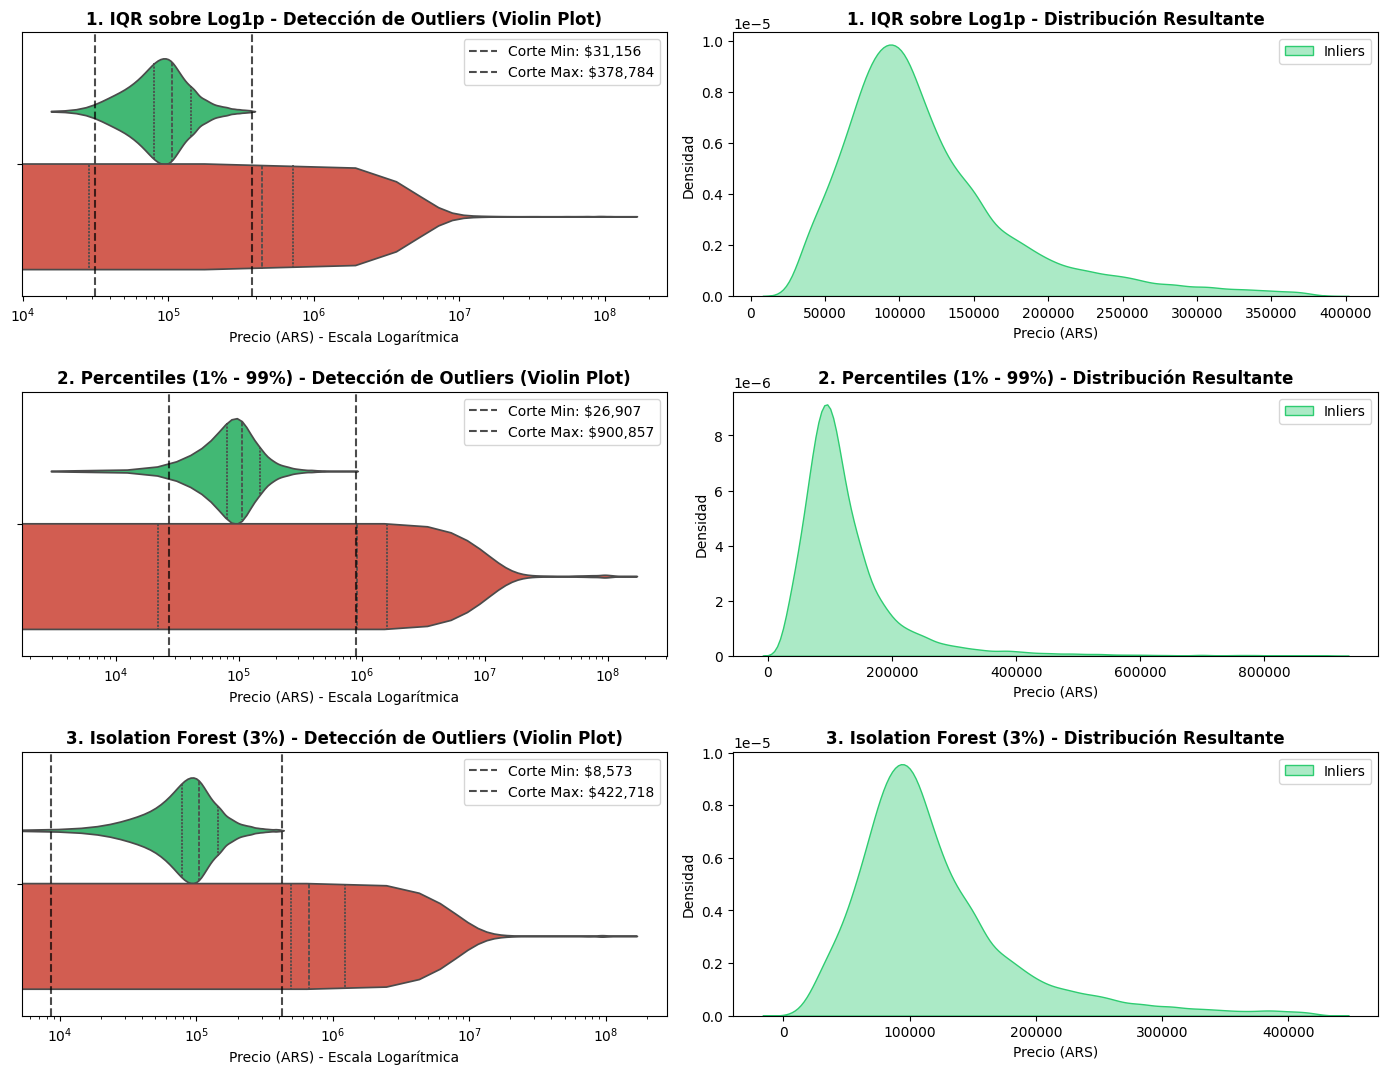

In [ ]:
# --- VISUALIZACIÓN COMPARATIVA ---
fig, axes = plt.subplots(3, 2, figsize=(14, 11))

methods = [
    ("1. IQR sobre Log1p", mask_iqr, lower_log, upper_log),
    ("2. Percentiles (1% - 99%)", mask_perc, p_low, p_high),
    ("3. Isolation Forest (3%)", mask_iso, df[mask_iso][target].min(), df[mask_iso][target].max())
]

for i, (name, mask, min_val, max_val) in enumerate(methods):
    sub_df = df.copy()
    sub_df['Estado'] = np.where(mask, 'Conservado (Inlier)', 'Descartado (Outlier)')

    # 1. Violin Plot: Compara Inliers vs Outliers descartados
    ax_v = axes[i, 0]
    sns.violinplot(
        data=sub_df,
        x=target,
        # y='Estado',
        hue='Estado',
        ax=ax_v,
        palette={'Conservado (Inlier)': '#2ecc71', 'Descartado (Outlier)': '#e74c3c'},
        inner='quartile',
        legend=False
    )

    ax_v.set_xscale('log') # Escala logarítmica para visibilizar los extremos ($160M)
    ax_v.set_title(f'{name} - Detección de Outliers (Violin Plot)', fontweight='bold')
    ax_v.set_xlabel('Precio (ARS) - Escala Logarítmica')
    ax_v.axvline(min_val, color='black', linestyle='--', alpha=0.7, label=f'Corte Min: ${min_val:,.0f}')
    ax_v.axvline(max_val, color='black', linestyle='--', alpha=0.7, label=f'Corte Max: ${max_val:,.0f}')
    ax_v.legend(loc='upper right')

    # 2. Distribución de Densidad (KDE): Muestra el subset resultante
    ax_d = axes[i, 1]
    sns.kdeplot(
        data=sub_df[sub_df['Estado'] == 'Conservado (Inlier)'],
        x=target,
        ax=ax_d,
        color='#2ecc71',
        fill=True,
        alpha=0.4,
        label='Inliers'
    )
    ax_d.set_title(f'{name} - Distribución Resultante', fontweight='bold')
    ax_d.set_xlabel('Precio (ARS)')
    ax_d.set_ylabel('Densidad')
    ax_d.legend(loc='upper right')

plt.tight_layout()
plt.show()

#### 1. IQR sobre Log1p (Normalización de Asimetría)

* **Límites Estadísticos Calculados:**
    - **$31,156 -> a  -> $378,784 ARS**.

* **Qué Observar en el Violin Plot (Izquierda):**
* El violín rojo (*Outliers* descartados) captura dos mundos: errores/precios irrisorios por debajo de $31k y toda la cola pesada de valores extremos por encima de $378k (llegando hasta $10^8$ ARS).

* El violín verde (*Inliers*) muestra una distribución muy simétrica e ideal alrededor de los $10^5$ ($100,000 ARS).


* **Distribución Resultante (Derecha):**
    * Genera una curva de densidad suave con moda cerca de los **$100,000 ARS**.

* **Conclusión para la Clase:** Es la técnica más consistente para modelos lineales (como Ridge) o redes neuronales, ya que acota el dominio reduciendo drásticamente el $Bias^2$ provocado por la asimetría de la cola derecha.

---

#### 2. Percentiles 1% - 99% (Recorte No Paramétrico)

* **Límites Estadísticos Calculados:** **$26,907 -> a -> $900,857 ARS**.


* **Qué Observar en el Violin Plot (Izquierda):**
* Al ser un corte rígido por porcentaje fijo (1% inferior y 1% superior), conserva un rango mucho más amplio en la parte alta ($900k vs $378k de IQR).


* El violín verde se extiende sensiblemente más hacia la derecha.


* **Distribución Resultante (Derecha):**
* La curva de densidad resultante conserva una **cola larga muy pronunciada (*right-skewed*)** entre $200,000 y $900,000 ARS.


* **Conclusión para la Clase:** Es un método agresivo conservando datos de gama alta. Si el modelo final es un árbol de decisión o un ensamble (Random Forest, XGBoost), este método funciona bien porque los árboles no sufren tanto con las colas largas; pero para regresiones lineales puede inflar el error residual ($RMSE$).

---

#### 3. Isolation Forest al 3% (Detección Algorítmica Unidimensional)

* **Límites Estadísticos Calculados:** **$8,573** a **$422,718 ARS**.


* **Qué Observar en el Violin Plot (Izquierda):**
* El algoritmo es más tolerante en la parte baja (deja ingresar precios desde $8,573 ARS).


* Esto sucede porque en el espacio unidimensional, las observaciones entre $8k y $31k no están tan "aisladas" como los departamentos de $10M+ ARS.


* **Distribución Resultante (Derecha):**
* Logra una densidad limpia hasta los $420k ARS, pero muestra un pequeño "hombro" cerca del origen ($0 - $30k).


* **Conclusión para la Clase:** Ilustra perfecto cómo funciona un método no supervisado basado en aislamiento. Para la parte superior actúa de forma similar a IQR Log, pero demuestra que en 1D necesita afinarse con reglas de negocio adicionales si se quieren evitar precios irrisorios en el extremo inferior.

***

### Cuadro Comparativo para la Pizarra

| Criterio | 1. IQR sobre Log1p | 2. Percentiles (1%–99%) | 3. Isolation Forest (3%) |
| --- | --- | --- | --- |
| **Rango de Retención** | $31k – $378k | $26k – $900k | $8.5k – $422k |
| **Tratamiento Cola Alta** | Criterio estadístico estricto | Permite valores muy altos | Criterio por aislamiento de densidad |
| **Forma de la Densidad** | Casi normal / campana limpia | Asimétrica con cola larga | Campana limpia con cola corta |
| **Recomendado para...** | Modelos Lineales / Redes | Modelos de Árboles (XGBoost / RF) | Filtros Multivariados Complejos |

In [ ]:
# Configuración y ajuste de Isolation Forest
iso = IsolationForest(contamination=0.03, random_state=RANDOM_STATE)
inliers_mask = iso.fit_predict(df[[target]]) == 1

# Filtrado del DataFrame
df = df[inliers_mask].copy()

# Definición de Features y Target
features = [
    'neighbourhood',
    'room_type',
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365'
]

X = df[features]
y = np.log1p(df[target])  # Transformación logarítmica para estabilizar varianza

***

In [ ]:
num_cols = [
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365'
]

cat_cols = ['neighbourhood', 'room_type']

### Dialéctica de Generalización (Bias, Varianza y Complejidad)

**Objetivo:** Mostrar cómo la capacidad/complejidad del modelo altera el balance entre Underfitting y Overfitting.

In [ ]:
# Dividimos una muestra de control para ilustrar la curva
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
    )

# Evaluamos Random Forest con distintas profundidades máximas
depths = [1, 3, 5, 8 ,10, 12, 20, None]
train_errors, val_errors = [], []

for d in depths:
    # Preprocesamiento integrado
    print(f"{d} ->  Profundidad Inicializada")
    preprocessor = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

    model = Pipeline([
        ('prep', preprocessor),
        ('rf', RandomForestRegressor(max_depth=d, n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1))
    ])

    model.fit(X_dev, y_dev)

    y_pred_train = model.predict(X_dev)
    y_pred_val = model.predict(X_test)

    train_errors.append(np.sqrt(mean_squared_error(y_dev, y_pred_train)))
    val_errors.append(np.sqrt(mean_squared_error(y_test, y_pred_val)))

for d, tr, val in zip(depths, train_errors, val_errors):
    print(f"Max Depth: {str(d):5s} | RMSE Train: {tr:.4f} | RMSE Val: {val:.4f} | Diff: {val-tr:.4f}")

Max Depth: 1     | RMSE Train: 0.4722 | RMSE Val: 0.4680 | Diff: -0.0043
Max Depth: 3     | RMSE Train: 0.4403 | RMSE Val: 0.4392 | Diff: -0.0011
Max Depth: 5     | RMSE Train: 0.4182 | RMSE Val: 0.4183 | Diff: 0.0001
Max Depth: 8     | RMSE Train: 0.3895 | RMSE Val: 0.4015 | Diff: 0.0121
Max Depth: 10    | RMSE Train: 0.3641 | RMSE Val: 0.3954 | Diff: 0.0312
Max Depth: 12    | RMSE Train: 0.3321 | RMSE Val: 0.3908 | Diff: 0.0587
Max Depth: 20    | RMSE Train: 0.2021 | RMSE Val: 0.3857 | Diff: 0.1837
Max Depth: None  | RMSE Train: 0.1476 | RMSE Val: 0.3862 | Diff: 0.2386


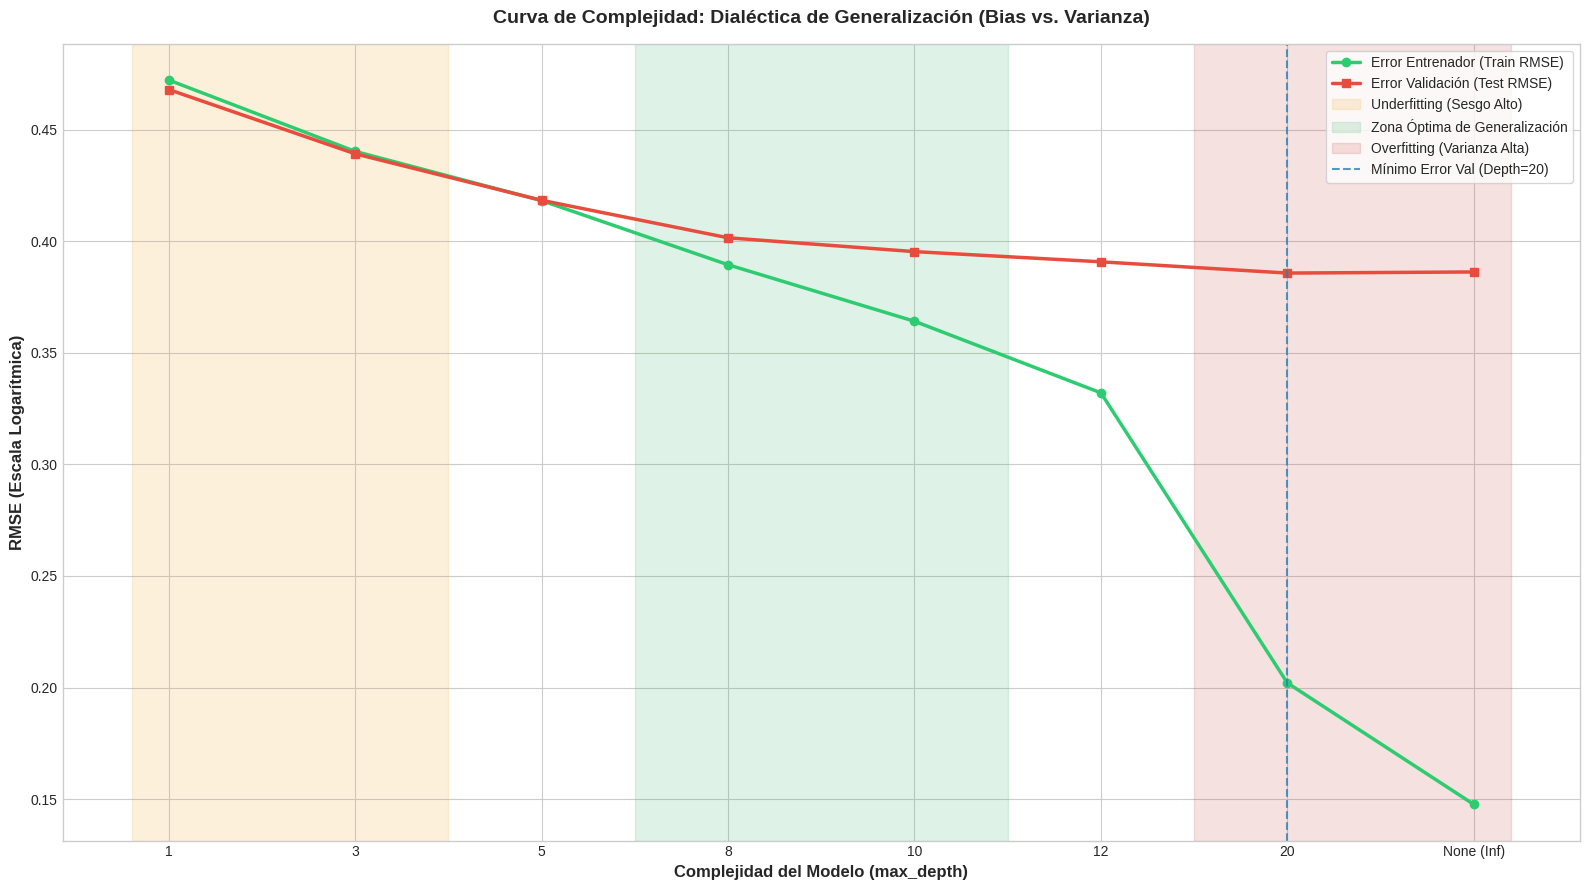

In [ ]:
depths_labels = [str(d) if d is not None else 'None (Inf)' for d in depths]
x_axis = np.arange(len(depths))

plt.figure(figsize=(16, 9))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

plt.plot(x_axis, train_errors, marker='o', linewidth=2.5, color='#2ecc71', label='Error Entrenador (Train RMSE)')
plt.plot(x_axis, val_errors, marker='s', linewidth=2.5, color='#e74c3c', label='Error Validación (Test RMSE)')

# Resaltar la zona de Underfitting, Óptima y Overfitting
plt.axvspan(-0.2, 1.5, color='#f39c12', alpha=0.15, label='Underfitting (Sesgo Alto)')
plt.axvspan(2.5, 4.5, color='#27ae60', alpha=0.15, label='Zona Óptima de Generalización')
plt.axvspan(5.5, 7.2, color='#c0392b', alpha=0.15, label='Overfitting (Varianza Alta)')

# Línea punteada en el óptimo (ej: depth=10 u 12)
best_idx = np.argmin(val_errors)
plt.axvline(x=best_idx, color='#2980b9', linestyle='--', alpha=0.8, label=f'Mínimo Error Val (Depth={depths_labels[best_idx]})')

plt.xticks(x_axis, depths_labels)
plt.xlabel('Complejidad del Modelo (max_depth)', fontsize=12, fontweight='bold')
plt.ylabel('RMSE (Escala Logarítmica)', fontsize=12, fontweight='bold')
plt.title('Curva de Complejidad: Dialéctica de Generalización (Bias vs. Varianza)', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

#### Planteos para clase:

* **`max_depth = 1` (Baja complejidad / Underfitting):** Alto error tanto en Train como en Test ($Bias^2$ dominante). El modelo simplifica en exceso la geografía y dinámica de precios de Buenos Aires (ej. trata igual a Palermo que a Lugano).
* **`max_depth = 20` o `None` (Alta complejidad / Overfitting):** Error en Train cercano a cero, pero el error de Validación se dispara o estanca ($Varianza$ dominante). El árbol memorizó las excentricidades de anuncios específicos.
* **Zona Óptima:** `max_depth` entre $8$ y $12$ logra el balance ideal disminuyendo el Error Total.



### Estrategias y Esquemas de Validación

**Objetivo:** Demostrar por qué un Hold-out simple puede ser engañoso y cómo $K$-Fold Cross-Validation refleja el rendimiento real.


In [ ]:
# Definición del Pipeline Estándar
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

pipeline_base = Pipeline([
    ('prep', preprocessor),
    ('rf', RandomForestRegressor(n_estimators=8, random_state=RANDOM_STATE, n_jobs=-1))
    # ('model', Ridge(alpha=1.0))
])

# Esquema K-Fold Cross-Validation (K=5) sobre el conjunto de desarrollo
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = cross_validate(
    pipeline_base,
    X_dev,
    y_dev,
    cv=kf,
    scoring='neg_root_mean_squared_error'
)

rmse_scores = -cv_results['test_score']
print(f"Resultados K-Fold RMSE (5 folds): {rmse_scores}")
print(f"Métrica Final: {rmse_scores.mean():.4f} +/- {rmse_scores.std():.4f}")

Resultados K-Fold RMSE (5 folds): [0.41047747 0.41037265 0.4088201  0.41652458 0.41521828]
Métrica Final: 0.4123 +/- 0.0030



#### Planteos para clase:

* **Muestreo e Incertidumbre:** Reportar la media ($\mu$) junto con la desviación estándar ($\sigma$) del error en los 5 *folds* le permite al estudiante medir qué tan sensible es el modelo a cambios en los datos de entrada.
* **Elección del Esquema:**
    * En predicción de precios (regresión), **K-Fold con Shuffle** es importante en este contexto *ver explicacion*.
    * Se aclara que si el problema fuera predecir si un departamento es "De Lujo" (Clasificación desbalanceada, $<5\%$ del dataset), usaríamos **Stratified K-Fold** para evitar *folds* sin la clase minoritaria.

***

*Explicacion:*

El uso de **K-Fold con Shuffle (barajado aleatorio)** es la norma en regresión (y en problemas con datos tabulares no temporales) principalmente por las siguientes tres razones técnicas y conceptuales:

*Eliminación de Sesgos por Orden de Carga (Sistemático o Implícito)*

En la práctica profesional, los datasets casi nunca vienen ordenados de forma puramente aleatoria:

* **Orden por Scraping o Geolocalización:** Es muy común que los datos de Airbnb se hayan recolectado barriendo barrio por barrio (primero todos los departamentos de Palermo, luego Recoleta, luego San Telmo).
* **Orden por Fecha o ID:** Pueden estar agrupados por fecha de publicación o por el ID del anfitrión.

Si aplicaras un **K-Fold sin shuffle** sobre datos ordenados por barrio:

* El *Fold 1* entrenaría sin ver jamás departamentos de Palermo.
* El *Fold 5* validaría únicamente sobre un barrio con precios radicalmente distintos al resto.
* **Consecuencia:** La varianza entre *folds* se dispararía de forma artificial, evaluando la capacidad del modelo para adivinar barrios no vistos en lugar de evaluar su capacidad de generalizar la relación precio-características.

---

*Garantía de la Hipótesis *i.i.d.* (Independientes e Idénticamente Distribuidas)*

La mayoría de los algoritmos de Machine Learning asumen que los datos de entrenamiento y validación provienen de la misma distribución subyacente ($i.i.d.$).

Al aplicar **Shuffle**:

* Se rompe cualquier correlación espuria causada por el orden de la fila.
* Se garantiza que cada uno de los $K$ subconjuntos mantenga **la misma media ($\mu$) y varianza ($\sigma^2$) del target (`price`) y de las features**, haciendo que los $K$ experimentos sean estadísticamente comparables entre sí.

---

*Estimación Imparcial de la Incertidumbre ($\mu \pm \sigma$)*

En el Eje 2 de la clase se busca reportar la métrica como $\text{Media} \pm \text{Desviación Estándar}$ (por ejemplo, $RMSE = 0.385 \pm 0.012$).

* **Con Shuffle:** La desviación estándar ($\sigma$) refleja únicamente la **incertidumbre muestral genuina** del modelo ante pequeñas variaciones de los datos.
* **Sin Shuffle:** La desviación estándar ($\sigma$) reflejaría el "accidente" de cómo quedaron repartidos los barrios o IDs en cada bloque, inflando el error y distorsionando el diagnóstico.

---

*¿Cuándo **NO** se debe usar Shuffle?*

Es fundamental dejar esta advertencia clara en clase:

1. **Series Temporales / Datos Secuenciales:** Si los datos dependen del tiempo (por ejemplo, predecir el precio del alquiler en base a la inflación mes a mes), **NUNCA se usa shuffle**. Usar shuffle en datos temporales introduce *Data Leakage* del futuro al pasado. En ese caso se utiliza `TimeSeriesSplit`.
2. **Grupos Fuertemente Correlacionados:** Si un mismo anfitrión tiene 50 departamentos idénticos en el dataset, hacer un shuffle simple puede enviar 40 de sus departamentos a Train y 10 a Validation (*Group Leakage*). En ese caso se usa `GroupKFold`.

### Optimización Controlada de Hiperparámetros

**Objetivo:** Aplicar la búsqueda de hiperparámetros dentro del bucle de validación sin violar la integridad del Test Set.


In [35]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingRandomSearchCV

class RFHalvingTuner:
    def __init__(self, preprocessor, model, random_state=RANDOM_STATE, cv=3):
        self.preprocessor = preprocessor
        self.random_state = random_state
        self.model = model
        self.cv = cv
        self.params = {
            'model__n_estimators': [50, 100, 200, 300],
            'model__max_depth': [6, 10, 15, 20, None],
            'model__min_samples_split': [2, 5, 10],
            'model__min_samples_leaf': [1, 2, 4]
        }
        self.best_params_ = None

    def fit(self, X, y):

        pipeline = Pipeline([
            ('prep', self.preprocessor),
            ('model', self.model )
        ])

        self.search_ = HalvingRandomSearchCV(
            estimator=pipeline,
            param_distributions=self.params,
            n_candidates=30,
            factor=3,
            min_resources='smallest',
            scoring='neg_root_mean_squared_error',
            cv=self.cv,
            random_state=self.random_state,
            n_jobs=-1,
            verbose=1
        )

        self.search_.fit(X, y)
        self.best_model_ = self.search_.best_estimator_
        print("Mejores Hiperparámetros encontrados:")
        print(self.search_.best_params_)
        self.best_params_ = self.search_.best_params_
        print(f"Mejor RMSE en CV: {-self.search_.best_score_:.4f}")
        return self

    def evaluate(self, X_test, y_test):
        y_pred = self.best_model_.predict(X_test)
        self.rmse_log_ = np.sqrt(mean_squared_error(y_test, y_pred))
        self.mae_ars_ = mean_absolute_error(np.expm1(y_test), np.expm1(y_pred))
        print("\n--- AUDITORÍA FINAL (TEST SET) ---")
        print(f"RMSE (Escala Log): {self.rmse_log_:.4f}")
        print(f"MAE (Escala Real ARS): ${self.mae_ars_:,.2f}")
        return self

In [36]:
random_forest = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)

rf_tuner_halving = RFHalvingTuner(
    preprocessor,
    model=random_forest,
    random_state=RANDOM_STATE
).fit(X_dev, y_dev)

rf_tuner_halving.evaluate(X_test, y_test)

n_iterations: 4
n_required_iterations: 4
n_possible_iterations: 8
min_resources_: 6
max_resources_: 21408
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 30
n_resources: 6
Fitting 3 folds for each of 30 candidates, totalling 90 fits
----------
iter: 1
n_candidates: 10
n_resources: 18
Fitting 3 folds for each of 10 candidates, totalling 30 fits
----------
iter: 2
n_candidates: 4
n_resources: 54
Fitting 3 folds for each of 4 candidates, totalling 12 fits
----------
iter: 3
n_candidates: 2
n_resources: 162
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Mejores Hiperparámetros encontrados:
{'model__n_estimators': 50, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_depth': 15}
Mejor RMSE en CV: 0.4290

--- AUDITORÍA FINAL (TEST SET) ---
RMSE (Escala Log): 0.3877
MAE (Escala Real ARS): $34,797.71


In [37]:
rf_tuner_halving.best_params_

{'model__n_estimators': 50,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 4,
 'model__max_depth': 15}

### Alternativa altamente usado en produccion: `Optuna`

In [33]:
! pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


### Esta es una version optimizada por que la anterior es para casos de mayor densidad

In [54]:
import optuna
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error


class RFOptuna:
    def __init__(self, preprocessor, random_state=RANDOM_STATE, cv=3,
                 final_n_estimators=300):
        self.preprocessor = preprocessor
        self.random_state = random_state
        self.cv = cv
        self.final_n_estimators = final_n_estimators

    def _prepare_folds(self, X, y):
        """Ajusta el preprocesador una vez por fold (sin leakage) y cachea el resultado."""
        y = np.asarray(y)
        kf = KFold(self.cv, shuffle=True, random_state=self.random_state)
        self.folds_ = []
        for tr, va in kf.split(X):
            prep = clone(self.preprocessor)
            Xtr = prep.fit_transform(X.iloc[tr])
            Xva = prep.transform(X.iloc[va])
            self.folds_.append((Xtr, y[tr], Xva, y[va]))

    def _objective(self, trial):
        params = dict(
            max_depth=trial.suggest_categorical('max_depth', [10, 15, 20, None]),
            min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 10),
            max_features=trial.suggest_float('max_features', 0.2, 0.6),
        )
        rmses = []
        for step, (Xtr, ytr, Xva, yva) in enumerate(self.folds_):
            rf = RandomForestRegressor(
                n_estimators=50,
                max_samples=0.5,
                random_state=self.random_state,
                n_jobs=-1,
                **params,
            )
            rf.fit(Xtr, ytr)
            rmses.append(np.sqrt(mean_squared_error(yva, rf.predict(Xva))))

            trial.report(np.mean(rmses), step)   # pruning entre folds
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(rmses))

    def fit(self, X, y, n_trials=20):
        self._prepare_folds(X, y)
        self.study_ = optuna.create_study(
            direction='minimize',
            sampler=optuna.samplers.TPESampler(seed=self.random_state),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=0),
        )
        self.study_.optimize(self._objective, n_trials=n_trials)
        self.best_params_ = self.study_.best_params
        self.best_cv_rmse_ = self.study_.best_value

        final_rf = RandomForestRegressor(
            n_estimators=self.final_n_estimators,
            random_state=self.random_state,
            n_jobs=-1,
            **self.best_params_,
        )
        self.best_model_ = Pipeline([
            ('prep', clone(self.preprocessor)),
            ('rf', final_rf),
        ]).fit(X, y)
        return self

    def evaluate(self, X_test, y_test):
        y_pred = self.best_model_.predict(X_test)
        self.rmse_log_ = np.sqrt(mean_squared_error(y_test, y_pred))
        self.mae_ars_ = mean_absolute_error(np.expm1(y_test), np.expm1(y_pred))
        print(f"RMSE (Escala Log): {self.rmse_log_:.4f}")
        print(f"MAE (Escala Real ARS): ${self.mae_ars_:,.2f}")
        return self


In [55]:
rf_tuner_optuna = RFOptuna(preprocessor).fit(X_dev, y_dev)

print(rf_tuner_optuna.best_params_)
print(f"Mejor RMSE en CV: {rf_tuner_optuna.study_.best_value:.4f}")

rf_tuner_optuna.evaluate(X_test, y_test)

[I 2026-10-26 13:00:56,221] A new study created in memory with name: no-name-896d17c8-8049-4b4e-9d50-0c0ed82dd391
[I 2026-10-26 13:01:03,947] Trial 0 finished with value: 0.397714197382473 and parameters: {'max_depth': 15, 'min_samples_leaf': 2, 'max_features': 0.26239780813448105}. Best is trial 0 with value: 0.397714197382473.
[I 2026-10-26 13:01:20,746] Trial 1 finished with value: 0.3942649631076372 and parameters: {'max_depth': 15, 'min_samples_leaf': 1, 'max_features': 0.5879639408647976}. Best is trial 1 with value: 0.3942649631076372.
[I 2026-10-26 13:01:25,753] Trial 2 finished with value: 0.4040241156653171 and parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'max_features': 0.4099025726528951}. Best is trial 1 with value: 0.3942649631076372.
[I 2026-10-26 13:01:35,089] Trial 3 finished with value: 0.3949537762617858 and parameters: {'max_depth': 20, 'min_samples_leaf': 3, 'max_features': 0.3465447373174767}. Best is trial 1 with value: 0.3942649631076372.
[I 2026-10-26 1

{'max_depth': None, 'min_samples_leaf': 1, 'max_features': 0.4381475031569092}
Mejor RMSE en CV: 0.3930
RMSE (Escala Log): 0.3809
MAE (Escala Real ARS): $33,974.26


## Cómo funciona Optuna

Optuna tiene tres conceptos:

- **Study**: la sesión de optimización completa. Guarda todos los intentos y sabe cuál fue el mejor.
- **Trial**: un intento individual. Optuna propone una combinación de hiperparámetros, la evaluás y devolvés un número.
- **Objective**: la función que vos escribís. Recibe un `trial`, entrena y evalúa un modelo con los hiperparámetros que el trial sugiere, y devuelve la métrica a optimizar.

La diferencia con `RandomizedSearchCV` o Halving es **cómo elige** qué probar. Por defecto Optuna usa **TPE (Tree-structured Parzen Estimator)**, una optimización bayesiana:

1. Los primeros trials (10 por defecto) son aleatorios, para explorar.
2. Con esos resultados, divide los intentos en "buenos" (el mejor cuartil aproximadamente) y "malos".
3. Modela la distribución de hiperparámetros de cada grupo y propone valores que son **probables en los buenos y poco probables en los malos**.
4. Repite: cada trial nuevo aprende de todos los anteriores.

Por eso con 20 o 30 trials suele llegar a resultados comparables a una búsqueda aleatoria de 100+ combinaciones. No recorre el espacio a ciegas: se concentra en las zonas prometedoras.

## Qué hace cada parte de tu clase

**`__init__`**: guarda el preprocessor, la semilla y el número de folds. No hace nada más.

**`_build(params)`**: arma un Pipeline nuevo (preprocessor + Random Forest) con los hiperparámetros recibidos. El `**params` desempaca el diccionario como argumentos de `RandomForestRegressor`, por ejemplo `n_estimators=100, max_depth=10`. Se usa tanto durante la búsqueda como para el modelo final.

**`_objective(trial, X, y)`**: es el corazón. Hace tres cosas:

- Define el espacio de búsqueda con `trial.suggest_*`. Cada llamada le pide a Optuna un valor: `suggest_int` para enteros (con `step=50` solo propone 50, 100, 150...), `suggest_categorical` para elegir de una lista.
- Evalúa esa combinación con `cross_val_score` (5 folds).
- Devuelve `-scores.mean()`. El scoring `neg_root_mean_squared_error` viene negativo (sklearn maximiza), así que se cambia el signo para tener el RMSE positivo, que es lo que Optuna va a **minimizar**.

**`fit(X, y, n_trials=20)`**:

- `create_study(direction='minimize')` crea el study indicando que queremos el RMSE más bajo posible.
- `optimize(...)` ejecuta el ciclo: Optuna propone parámetros, llama al objective, recibe el RMSE, aprende, y repite 20 veces. El `lambda` sirve para pasarle `X` e `y` al objective, porque Optuna solo le entrega el `trial`.
- `best_params` guarda la mejor combinación encontrada.
- Por último **reentrena** un modelo con esos parámetros sobre todo `X`, porque `cross_val_score` entrena modelos temporales y no devuelve ninguno.

**`evaluate`**: predice sobre el test set y calcula RMSE en escala log y MAE en pesos (con `expm1` para deshacer el log).

## Cosas a tener en cuenta

- **Velocidad**: aplica lo mismo que vimos con Halving. Tenés `n_jobs=-1` dentro del Random Forest, lo cual está bien acá porque `cross_val_score` no paraleliza por defecto, así que hay un solo nivel de paralelismo. Si el tiempo sigue siendo alto, reducí `n_trials` o `cv`.
- **Reproducibilidad**: `create_study` no usa `random_state`, así que cada corrida da resultados distintos. Para fijarlo: `sampler=optuna.samplers.TPESampler(seed=self.random_state)`.
- **Ventaja práctica**: podés mirar `study_.trials_dataframe()` para ver todos los intentos, y `optuna.visualization.plot_optimization_history(study_)` para ver cómo fue mejorando.

In [46]:
sample_inferencia = [
    {
        "id": 476044,
        "name": "Casabierta, style in Palermo BA.",
        "neighbourhood": "Palermo",
        "room_type": "Entire home/apt",
        "latitude": -34.58718,
        "longitude": -58.4312,
        "price": 415838,
        "minimum_nights": 2,
        "number_of_reviews": 312,
        "reviews_per_month": 1.81,
        "calculated_host_listings_count": 1,
        "availability_365": 232,
    },
    {
        "id": 487707,
        "name": "A cosy and bright flat in La Boca",
        "neighbourhood": "Boca",
        "room_type": "Entire home/apt",
        "latitude": -34.63255,
        "longitude": -58.35777,
        "price": 52258,
        "minimum_nights": 7,
        "number_of_reviews": 13,
        "reviews_per_month": 0.09,
        "calculated_host_listings_count": 1,
        "availability_365": 355,
    },
    {
        "id": 521783,
        "name": "Lilac Suite - Palacio Nr San Telmo / private bath",
        "neighbourhood": "Constitucion",
        "room_type": "Private room",
        "latitude": -34.61954,
        "longitude": -58.38417,
        "price": 77206,
        "minimum_nights": 2,
        "number_of_reviews": 168,
        "reviews_per_month": 0.98,
        "calculated_host_listings_count": 6,
        "availability_365": 90,
    },
    {
        "id": 521338,
        "name": "LUXURY PENTHOUSE, FABULOUS TERRACE",
        "neighbourhood": "Recoleta",
        "room_type": "Entire home/apt",
        "latitude": -34.58838,
        "longitude": -58.38925,
        "price": 457552,
        "minimum_nights": 7,
        "number_of_reviews": 10,
        "reviews_per_month": 0.06,
        "calculated_host_listings_count": 2,
        "availability_365": 135,
    },
]

# Para pasar estos diccionarios directo al modelo o pipeline:
df_inferencia = pd.DataFrame(sample_inferencia)

df_inferencia

,id,name,neighbourhood,room_type,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,476044,"Casabierta, style in Palermo BA.",Palermo,Entire home/apt,-34.59,-58.43,415838,2,312,1.81,1,232
1,487707,A cosy and bright flat in La Boca,Boca,Entire home/apt,-34.63,-58.36,52258,7,13,0.09,1,355
2,521783,Lilac Suite - Palacio Nr San Telmo / private bath,Constitucion,Private room,-34.62,-58.38,77206,2,168,0.98,6,90
3,521338,"LUXURY PENTHOUSE, FABULOUS TERRACE",Recoleta,Entire home/apt,-34.59,-58.39,457552,7,10,0.06,2,135


In [47]:
def inferencia_tunnings(df_inferencia, tunner, z=1.96) -> pd.DataFrame:
    rmse_log = tunner.rmse_log_
    X_inf = df_inferencia.drop(columns=["id", "name", "price"])
    pred_log = tunner.best_model_.predict(X_inf)

    resultados = pd.DataFrame({
    "name": df_inferencia["name"],
    "neighbourhood": df_inferencia["neighbourhood"],
    "room_type": df_inferencia["room_type"],
    "precio_real": df_inferencia["price"],
    "prediccion": np.expm1(pred_log),
    "ic_inf": np.expm1(pred_log - z * rmse_log).clip(min=0),
    "ic_sup": np.expm1(pred_log + z * rmse_log),
    })

    resultados["dentro_ic"] = resultados["precio_real"].between(
        resultados["ic_inf"], resultados["ic_sup"]
    )

    # 4. Salida para la clase
    print("DEMOSTRACIÓN: PREDICCIÓN E INTERVALO (95%)")
    for i, r in enumerate(resultados.itertuples(), start=1):
        print(f"\n[Ejemplo {i}] {r.name}")
        print(f" ├─ Ubicación/Tipo:  {r.neighbourhood} | {r.room_type}")
        print(f" ├─ Precio Real:     ${r.precio_real:>12,.0f} ARS")
        print(f" ├─ Predicción ML:   ${r.prediccion:>12,.0f} ARS")
        print(f" ├─ Rango 95%:       [ ${r.ic_inf:,.0f}  ──  ${r.ic_sup:,.0f} ] ARS")
        print(f" └─ Real dentro del rango: {'Sí' if r.dentro_ic else 'No'}")

    print(f"\nCobertura: {resultados['dentro_ic'].mean():.0%} de los ejemplos dentro del rango")
    return resultados

In [48]:
# Resultados con Halving Search
resultados = inferencia_tunnings(df_inferencia,rf_tuner_halving)


DEMOSTRACIÓN: PREDICCIÓN E INTERVALO (95%)

[Ejemplo 1] Casabierta, style in Palermo BA.
 ├─ Ubicación/Tipo:  Palermo | Entire home/apt
 ├─ Precio Real:     $     415,838 ARS
 ├─ Predicción ML:   $     131,742 ARS
 ├─ Rango 95%:       [ $61,614  ──  $281,690 ] ARS
 └─ Real dentro del rango: No

[Ejemplo 2] A cosy and bright flat in La Boca
 ├─ Ubicación/Tipo:  Boca | Entire home/apt
 ├─ Precio Real:     $      52,258 ARS
 ├─ Predicción ML:   $     115,754 ARS
 ├─ Rango 95%:       [ $54,136  ──  $247,503 ] ARS
 └─ Real dentro del rango: No

[Ejemplo 3] Lilac Suite - Palacio Nr San Telmo / private bath
 ├─ Ubicación/Tipo:  Constitucion | Private room
 ├─ Precio Real:     $      77,206 ARS
 ├─ Predicción ML:   $      57,070 ARS
 ├─ Rango 95%:       [ $26,690  ──  $122,026 ] ARS
 └─ Real dentro del rango: Sí

[Ejemplo 4] LUXURY PENTHOUSE, FABULOUS TERRACE
 ├─ Ubicación/Tipo:  Recoleta | Entire home/apt
 ├─ Precio Real:     $     457,552 ARS
 ├─ Predicción ML:   $      89,710 ARS
 ├─ Rango 

In [56]:
# Resultados con Optuna
resultados = inferencia_tunnings(df_inferencia,rf_tuner_optuna)


DEMOSTRACIÓN: PREDICCIÓN E INTERVALO (95%)

[Ejemplo 1] Casabierta, style in Palermo BA.
 ├─ Ubicación/Tipo:  Palermo | Entire home/apt
 ├─ Precio Real:     $     415,838 ARS
 ├─ Predicción ML:   $     242,350 ARS
 ├─ Rango 95%:       [ $114,879  ──  $511,265 ] ARS
 └─ Real dentro del rango: Sí

[Ejemplo 2] A cosy and bright flat in La Boca
 ├─ Ubicación/Tipo:  Boca | Entire home/apt
 ├─ Precio Real:     $      52,258 ARS
 ├─ Predicción ML:   $      97,139 ARS
 ├─ Rango 95%:       [ $46,046  ──  $204,927 ] ARS
 └─ Real dentro del rango: Sí

[Ejemplo 3] Lilac Suite - Palacio Nr San Telmo / private bath
 ├─ Ubicación/Tipo:  Constitucion | Private room
 ├─ Precio Real:     $      77,206 ARS
 ├─ Predicción ML:   $      65,563 ARS
 ├─ Rango 95%:       [ $31,078  ──  $138,312 ] ARS
 └─ Real dentro del rango: Sí

[Ejemplo 4] LUXURY PENTHOUSE, FABULOUS TERRACE
 ├─ Ubicación/Tipo:  Recoleta | Entire home/apt
 ├─ Precio Real:     $     457,552 ARS
 ├─ Predicción ML:   $      94,602 ARS
 ├─ Rango

In [ ]:
res = resultados.sort_values("prediccion").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(6, 6))
ax.errorbar(res["precio_real"], res["prediccion"],
            yerr=[res["prediccion"] - res["ic_inf"], res["ic_sup"] - res["prediccion"]],
            fmt="o", ecolor="lightsteelblue", capsize=3)
lim = [res["ic_inf"].min(), res["ic_sup"].max()]
ax.plot(lim, lim, "k--", label="Predicción perfecta")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Precio real (ARS)"); ax.set_ylabel("Predicción (ARS)")
ax.legend(); plt.show()